# 03 · Fine-tuning a language model (DistilBERT)

**What this does.** Teaches a pre-trained language model, **DistilBERT**, to read reviews and say positive, neutral or negative. Then it checks, on the **same** 14,996 unseen test reviews as the baseline, whether it's worth the extra cost.

**Why a language model.** The baseline (notebook 02) counts words. It can't tell *"not bad"* from *"bad"*, or weigh *"great food **but** awful service"*. DistilBERT has already read a huge amount of English, so it understands word order, negation and context. **Fine-tuning** adjusts it with our labelled reviews so that understanding is pointed at our task.

**Where it ran.** Training needs a GPU, which the laptop doesn't have. It ran on a **free Kaggle notebook** with an Nvidia T4 GPU, started by `scripts/kaggle_train.py full`:
1. The three splits (text, label and shop type only) and a zip of our `review_intel` package were uploaded as a **private** Kaggle dataset.
2. A private Kaggle notebook ran the same training code the laptop tests run (`review_intel.models.train`): first on all three shop types, then again **without appliances** (section 5).
3. It scored the test reviews on the GPU, and its output folder was downloaded to `pipeline/models/kaggle/full/`.

This notebook reads those downloaded results and does the evaluation on the laptop, so re-running it costs nothing and never retrains.

In [1]:
import json
import shutil

import matplotlib.pyplot as plt
import pandas as pd

from review_intel import config
from review_intel.models.distilbert import TrainConfig, scores_from_probs
from review_intel.models.metrics import evaluate, evaluate_by_domain, save_metrics

FIG = config.REPORTS_DIR / "figures"
RUN = config.MODELS_DIR / "kaggle" / "full"  # downloaded by scripts/kaggle_train.py full
pd.set_option("display.max_colwidth", 200)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_parquet(config.INTERIM_DIR / "reviews.parquet")
train, val, test = (df[df["split"] == s].reset_index(drop=True) for s in ("train", "val", "test"))
baseline = json.loads((config.REPORTS_DIR / "metrics" / "baseline.json").read_text())
print(f"train {len(train):,} · val {len(val):,} · test {len(test):,}")

train 119,976 · val 15,028 · test 14,996


## 1. Settings

- **3 passes (epochs) at most** over the training reviews. It **stops early** if validation macro F1 stops improving, and keeps the best epoch.
- **Each review is read up to 256 word-pieces long**, which covers about 95% of reviews in full.
- **Class weights** make neutral mistakes count for more, as in the baseline.
- **Mixed precision (fp16)**: the GPU does most of its maths in 16-bit numbers, which is about twice as fast with no loss in accuracy here.

In [2]:
result = json.loads((RUN / "full" / "result.json").read_text())
print(json.dumps(result["config"], indent=1))
assert result["config"] == TrainConfig().to_dict(), "the downloaded run used different settings"
print(f"\nTrained on {result['n_train']:,} reviews · {result['device']}")

{
 "model": "distilbert-base-uncased",
 "max_len": 256,
 "epochs": 3,
 "lr": 5e-05,
 "batch_size": 32,
 "fp16": true,
 "early_stopping_patience": 1,
 "seed": 42,
 "gpu": "T4",
 "timeout_s": 3600,
 "samples_per_s": 250.0,
 "holdout_domain": null
}

Trained on 119,976 reviews · Tesla T4


## 2. Training

One row per epoch: the **validation macro F1**, how good the model is on reviews it isn't trained on, and the **validation loss** (how wrong its probabilities are; lower is better).

In [3]:
history = pd.DataFrame(result["history"])
print(f"run {result['run_id']} · {result['seconds'] / 60:,.1f} GPU minutes · {result['samples_per_s']} reviews/s")
log = next(RUN.glob("*.log"), None)
if log:  # Kaggle saves the notebook's printed output as a JSON list of {stream_name, time, data}
    events = json.loads(log.read_text(encoding="utf-8"))
    print("".join(e["data"] for e in events if e["stream_name"] == "stdout" and not e["data"].startswith("{")))
history.round(4)

run 9501c6c56b68 · 27.0 GPU minutes · 222.0 reviews/s
torch 2.11.0+cu128 · transformers 5.22.1 · GPU Tesla T4
== full ==
Training on 119,976 reviews, validating on 15,028 · Tesla T4
epoch 1: train loss 0.486 · val macro F1 0.689 · 562 s
epoch 2: train loss 0.384 · val macro F1 0.766 · 1,091 s
epoch 3: train loss 0.247 · val macro F1 0.759 · 1,620 s
Done in 1,621 s · best val macro F1 0.766 · run 9501c6c56b68
full: scored 14,996 test reviews
== holdout ==
Training on 80,000 reviews, validating on 10,000 · Tesla T4
epoch 1: train loss 0.491 · val macro F1 0.742 · 420 s
epoch 2: train loss 0.394 · val macro F1 0.757 · 818 s
epoch 3: train loss 0.258 · val macro F1 0.765 · 1,216 s
Done in 1,217 s · best val macro F1 0.765 · run e72ad1b343cc
holdout: scored 4,996 test reviews



,epoch,val_macro_f1,val_loss
0,1.0,0.6887,0.5175
1,2.0,0.7658,0.4990
2,3.0,0.7587,0.6100


## 3. The test: same 14,996 reviews as the baseline

In [4]:
def load_scores(folder):
    scored = json.loads((folder / "test_probs.json").read_text())
    return scored["rows"], pd.DataFrame(scores_from_probs(scored["probs"]))


rows, scored = load_scores(RUN / "full")
assert rows == list(range(len(test))), "test rows came back out of order"
test["pred"], test["score"], test["confidence"] = scored["label"], scored["score"], scored["confidence"]
m = evaluate(test["label"], test["pred"])
pd.DataFrame({
    "DistilBERT": {"macro F1": m["macro_f1"], "accuracy": m["accuracy"], "neutral F1": m["per_class"]["neutral"]["f1"]},
    "baseline (TF-IDF + LR)": {"macro F1": baseline["macro_f1"], "accuracy": baseline["accuracy"], "neutral F1": baseline["per_class"]["neutral"]["f1"]},
}).T.round(3)

,macro F1,accuracy,neutral F1
DistilBERT,0.761,0.887,0.492
baseline (TF-IDF + LR),0.732,0.872,0.445


In [5]:
pd.DataFrame(m["per_class"]).T.round(3)

,precision,recall,f1,support
negative,0.856,0.819,0.837,2751.0
neutral,0.401,0.636,0.492,1155.0
positive,0.979,0.930,0.954,11090.0


**Confusion matrices side by side** (each row as percentages): where each true label's reviews end up.

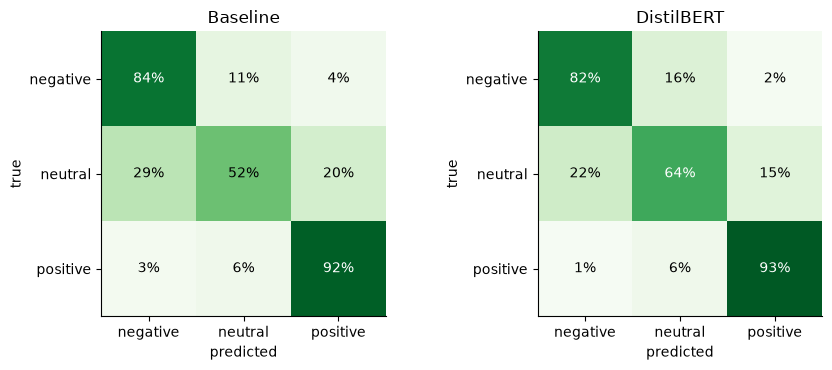

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (name, conf) in zip(axes, [("Baseline", baseline["confusion"]), ("DistilBERT", m["confusion"])], strict=True):
    cm = pd.DataFrame(conf, index=config.LABELS, columns=config.LABELS)
    pct = cm.div(cm.sum(axis=1), axis=0) * 100
    ax.imshow(pct, cmap="Greens", vmin=0, vmax=100)
    ax.set_xticks(range(3), config.LABELS); ax.set_yticks(range(3), config.LABELS)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(name)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{pct.iloc[i, j]:.0f}%", ha="center", va="center", color="white" if pct.iloc[i, j] > 60 else "black")
plt.tight_layout(); plt.savefig(FIG / "03_confusion_vs_baseline.png"); plt.show()

## 4. Every kind of shop

In [7]:
by_domain = evaluate_by_domain(test, "pred")
pd.DataFrame({d: {"DistilBERT macro F1": v["macro_f1"], "baseline macro F1": baseline["by_domain"][d]["macro_f1"],
                  "DistilBERT neutral F1": v["per_class"]["neutral"]["f1"], "baseline neutral F1": baseline["by_domain"][d]["per_class"]["neutral"]["f1"]}
              for d, v in by_domain.items()}).T.round(3)

,DistilBERT macro F1,baseline macro F1,DistilBERT neutral F1,baseline neutral F1
appliances,0.738,0.688,0.401,0.301
grocery,0.746,0.722,0.452,0.424
restaurant,0.776,0.753,0.555,0.510


## 5. A shop type it has never seen

The real product must work for shops it wasn't trained on: salons, clothing stores. To test that, a second model was trained **without any appliance reviews** and tested on appliances only. Comparing it with the model that *did* see appliances shows how much it loses on a new kind of shop.

In [8]:
HOLDOUT = "appliances"
result_h = json.loads((RUN / "holdout" / "result.json").read_text())
rows_h, scored_h = load_scores(RUN / "holdout")
test_h = test.loc[rows_h].reset_index(drop=True)
assert set(test_h["domain"]) == {HOLDOUT}
m_h = evaluate(test_h["label"], scored_h["label"])
pd.DataFrame({
    "never saw appliances": {"macro F1": m_h["macro_f1"], "neutral F1": m_h["per_class"]["neutral"]["f1"]},
    "trained on all three": {"macro F1": by_domain[HOLDOUT]["macro_f1"], "neutral F1": by_domain[HOLDOUT]["per_class"]["neutral"]["f1"]},
    "baseline (all three)": {"macro F1": baseline["by_domain"][HOLDOUT]["macro_f1"], "neutral F1": baseline["by_domain"][HOLDOUT]["per_class"]["neutral"]["f1"]},
}).T.round(3)

,macro F1,neutral F1
never saw appliances,0.699,0.346
trained on all three,0.738,0.401
baseline (all three),0.688,0.301


## 6. Where does it still go wrong?

These are 30 reviews it got wrong, read one by one. The categories in the key findings come from reading these.

In [9]:
wrong = test[test["label"] != test["pred"]].sample(30, random_state=config.SEED)
wrong.assign(text=wrong["text"].str.slice(0, 260), score=wrong["score"].round(2))[["domain", "stars", "label", "pred", "score", "text"]]

[Output removed before publishing: it shows review text, which the Yelp and Amazon licences don't allow us to republish. Run the notebook locally to see it.]


## 7. What it cost, and saving the results

Kaggle's GPU is free (about 30 hours a week per account), so the cost is GPU time from that allowance, not money.

In [10]:
gpu_min = (result["seconds"] + result_h["seconds"]) / 60
print(f"GPU time used: {gpu_min:,.0f} min of training (plus a few minutes of start-up and scoring) · $0")
save_metrics("distilbert", {**m, "by_domain": by_domain, "run_id": result["run_id"], "history": result["history"],
                            "train_seconds": result["seconds"], "trained_on": "Kaggle T4 (free)"}, test_size=len(test))
save_metrics("distilbert_holdout", {**m_h, "holdout_domain": HOLDOUT, "run_id": result_h["run_id"]}, test_size=len(test_h))
dest = config.MODELS_DIR / "distilbert" / result["run_id"]
shutil.copytree(RUN / "full" / "model", dest, dirs_exist_ok=True)
(config.MODELS_DIR / "distilbert" / "LATEST").write_text(result["run_id"])
print("model saved to", dest.relative_to(config.REPO_ROOT), "· the app's analysis now uses it (models/predict.py)")

GPU time used: 47 min of training (plus a few minutes of start-up and scoring) · $0
model saved to pipeline\models\distilbert\9501c6c56b68 · the app's analysis now uses it (models/predict.py)


## Key findings

1. **DistilBERT beats the baseline on every measure**: macro F1 **0.761 vs 0.732**, accuracy 88.7% vs 87.2%, and neutral F1 **0.492 vs 0.445**. It's now the model the app uses (`models/predict.py` picks it up from `LATEST`).
2. **The second pass was the best.** Validation macro F1 went 0.689 → **0.766** → 0.759. By the third pass the model was memorising the training reviews (training loss kept falling, validation loss rose from 0.50 to 0.61), so the saved model is the pass-2 one. More passes wouldn't help; more varied data would.
3. **It helps most where the baseline was weakest.** Appliances gained the most (0.688 → 0.738 macro F1; neutral F1 0.301 → 0.401). Restaurants remain the easiest (0.776), because Yelp reviews are longer and say more.
4. **A shop type it has never seen still works, with a cost.** Trained without any appliance reviews, it scores **0.699** on appliances: 0.04 below the model that saw them, yet still above the baseline that *was* trained on them (0.688). For new shop types such as salons, expect quality a little below the tested ones.
5. **Neutral is still the hard part, and the errors are mostly "neutral" calls.** Neutral recall is 64% but precision only 40%: 647 positive and 449 negative reviews were called neutral. The class weights deliberately push this way, so mixed reviews aren't drowned out. Clear mix-ups are rare: 48 negatives called positive, 127 positives called negative.
6. **Reading 30 mistakes, they fall into four groups:**
   - **Mixed reviews:** a 5★ review saying a part works perfectly until the dishwasher burned it out again; a 4★ calling a snack convenient but disliking its flavour. Neutral is a fair reading.
   - **Stars that disagree with the text:** a 1★ review that ends by giving the shop five stars, a 4★ that is mostly about shipping damage. Here the star label is the questionable part.
   - **Mild complaints that are clearly negative to a person:** 2★ reviews that just say a product is too light, or not very fresh. The model is too soft on short, plain-worded complaints.
   - **Long stories that change direction:** a review that opens with a very bad first impression and ends happily, or a 1★ where a fix worked for a week and then the machine died. The model reads at most 256 word-pieces and can weigh the wrong part.
7. **Cost: $0.** 47 GPU-minutes of Kaggle's free weekly allowance (30 hours) on a T4.